### Kết quả tái hiện bước đầu

Mô hình BSRBF-KAN được triển khai trên bộ kiểm thử chính thức UJIIndoorLoc gồm 1.111 mẫu. Sai số định vị trung bình tổng hợp đạt 43,180 m, cao hơn 34,750 m so với mức 8,430 m được báo cáo trong KSE 2025. Sai số trung bình lần lượt tại Building 0, Building 1 và Building 2 là 38,406 m, 53,510 m và 40,893 m.

Tuy nhiên, phân tích đầu ra cho thấy kết quả trên không phản ánh một mô hình định vị đã học được ánh xạ RSS–tọa độ. Độ lệch chuẩn của tọa độ dự đoán gần bằng 0 tại cả ba tòa nhà. Trong không gian tọa độ đã chuẩn hóa, độ lệch chuẩn đầu ra chỉ nằm trong khoảng 10⁻⁶ đến 10⁻⁸, trong khi dữ liệu thực có độ lệch chuẩn xấp xỉ 1. Điều này cho thấy mô hình hội tụ về nghiệm gần như hằng số và trả về gần cùng một tọa độ cho các Wi-Fi fingerprint khác nhau.

Hiện tượng trên cũng phù hợp với MSE huấn luyện duy trì xấp xỉ 1. Do tọa độ mục tiêu được chuẩn hóa về trung bình 0 và phương sai 1, một mô hình luôn dự đoán giá trị gần 0 có MSE xấp xỉ 1. Sau phép biến đổi ngược, giá trị này tương ứng với vị trí gần tọa độ trung bình của dữ liệu huấn luyện trong từng tòa nhà.

Vì vậy, sai số 43,180 m chưa được xem là phép tái hiện trực tiếp hiệu năng 8,430 m của KSE 2025. Kết quả hiện tại cho thấy pipeline tái hiện gặp hiện tượng prediction collapse. Nguyên nhân cần tiếp tục được xác định giữa quy trình tiền xử lý và chuẩn hóa dữ liệu, thiết lập hồi quy, kiến trúc BSRBF-KAN nhiều tầng và quá trình tối ưu.

Bước kiểm chứng tiếp theo sử dụng MLP baseline từ cùng mã nguồn tác giả với toàn bộ pipeline dữ liệu và huấn luyện được giữ nguyên. Thí nghiệm đối chứng này nhằm xác định prediction collapse xuất phát từ pipeline chung hay riêng quá trình tối ưu của kiến trúc BSRBF-KAN.

Import thư viện

In [ ]:
import os
import math
import copy
import random
import shutil
import zipfile
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

Cấu hình thí nghiệm

In [ ]:
# =============================================================================
# CONFIG
# =============================================================================

SEED = 42

BATCH_SIZE = 64

GRID_SIZE = 4
SPLINE_ORDER = 3

# Stage 1: train last layers first
STAGE1_EPOCHS = 30
STAGE1_LR = 3e-4

# Stage 2: full-network fine tuning
STAGE2_EPOCHS = 80
PATIENCE = 15

VAL_SIZE = 0.15

HIDDEN = [
    512, 512,
    256, 256,
    128, 128,
    64, 64
]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("=" * 90)
print("BSRBF-KAN × OFFICIAL UJIIndoorLoc")
print("TWO-STAGE TRAINING")
print("=" * 90)

print("PyTorch :", torch.__version__)
print("Device  :", DEVICE)

if torch.cuda.is_available():
    print("GPU     :", torch.cuda.get_device_name(0))

print("=" * 90)

BSRBF-KAN × OFFICIAL UJIIndoorLoc
TWO-STAGE TRAINING
PyTorch : 2.11.0+cu130
Device  : cuda
GPU     : Tesla T4


Đây chính xác là cấu hình two-stage trong file: Stage 1 = 30 epoch, LR 3e-4; Stage 2 = 80 epoch; patience = 15 và internal validation = 15%

Radial Basis Function

In [ ]:
class RadialBasisFunction(nn.Module):

    def __init__(
        self,
        grid_min=-1.5,
        grid_max=1.5,
        num_grids=8,
        denominator=None
    ):
        super().__init__()

        grid = torch.linspace(
            grid_min,
            grid_max,
            num_grids
        )

        self.grid = nn.Parameter(
            grid,
            requires_grad=False
        )

        self.denominator = (
            denominator
            or
            (grid_max - grid_min) / (num_grids - 1)
        )

    def forward(self, x):

        return torch.exp(
            -(
                (
                    x[..., None]
                    - self.grid
                )
                / self.denominator
            ) ** 2
        )

BSRBF-KAN Layer

In [ ]:
class BSRBF_KANLayer(nn.Module):

    def __init__(
        self,
        input_dim,
        output_dim,
        grid_size=5,
        spline_order=3,
        base_activation=nn.SiLU,
        grid_range=(-1.5, 1.5)
    ):
        super().__init__()

        self.input_dim = input_dim
        self.output_dim = output_dim

        self.grid_size = grid_size
        self.spline_order = spline_order

        self.layernorm = nn.LayerNorm(
            input_dim
        )

        self.base_activation = (
            base_activation()
        )

        # ================================================================
        # Base branch
        # ================================================================

        self.base_weight = nn.Parameter(
            torch.empty(
                output_dim,
                input_dim
            )
        )

        nn.init.kaiming_uniform_(
            self.base_weight,
            a=math.sqrt(5)
        )

        # ================================================================
        # BSRBF branch
        # ================================================================

        self.spline_weight = nn.Parameter(
            torch.empty(
                output_dim,
                input_dim * (
                    grid_size
                    + spline_order
                )
            )
        )

        nn.init.kaiming_uniform_(
            self.spline_weight,
            a=math.sqrt(5)
        )

        self.rbf = RadialBasisFunction(
            grid_min=grid_range[0],
            grid_max=grid_range[1],
            num_grids=(
                grid_size
                + spline_order
            )
        )

        h = (
            grid_range[1]
            - grid_range[0]
        ) / grid_size

        grid = (
            (
                torch.arange(
                    -spline_order,
                    grid_size
                    + spline_order
                    + 1
                )
                * h
                + grid_range[0]
            )
            .expand(
                input_dim,
                -1
            )
            .contiguous()
        )

        self.register_buffer(
            "grid",
            grid
        )

    # =====================================================================
    # B-SPLINE
    # =====================================================================

    def b_splines(self, x):

        assert x.dim() == 2
        assert x.size(1) == self.input_dim

        grid = self.grid

        x = x.unsqueeze(-1)

        bases = (
            (
                x >= grid[:, :-1]
            )
            &
            (
                x < grid[:, 1:]
            )
        ).to(x.dtype)

        for k in range(
            1,
            self.spline_order + 1
        ):

            bases = (
                (
                    (
                        x
                        - grid[:, :-(k + 1)]
                    )
                    /
                    (
                        grid[:, k:-1]
                        - grid[:, :-(k + 1)]
                    )
                )
                * bases[:, :, :-1]
            ) + (
                (
                    (
                        grid[:, k + 1:]
                        - x
                    )
                    /
                    (
                        grid[:, k + 1:]
                        - grid[:, 1:-k]
                    )
                )
                * bases[:, :, 1:]
            )

        return bases.contiguous()

    # =====================================================================
    # FORWARD
    # =====================================================================

    def forward(self, x):

        x = self.layernorm(x)

        # Base branch
        base_output = F.linear(
            self.base_activation(x),
            self.base_weight
        )

        # B-spline branch
        bs_output = (
            self
            .b_splines(x)
            .reshape(
                x.size(0),
                -1
            )
        )

        # RBF branch
        rbf_output = (
            self
            .rbf(x)
            .reshape(
                x.size(0),
                -1
            )
        )

        # Combined BSRBF
        bsrbf_output = (
            bs_output
            + rbf_output
        )

        bsrbf_output = F.linear(
            bsrbf_output,
            self.spline_weight
        )

        return (
            base_output
            + bsrbf_output
        )

BSRBF-KAN Model

In [ ]:
class BSRBF_KAN(nn.Module):

    def __init__(
        self,
        layers_hidden,
        grid_size=5,
        spline_order=3,
        base_activation=nn.SiLU
    ):
        super().__init__()

        self.layers = nn.ModuleList()

        for input_dim, output_dim in zip(
            layers_hidden,
            layers_hidden[1:]
        ):

            self.layers.append(
                BSRBF_KANLayer(
                    input_dim,
                    output_dim,
                    grid_size=grid_size,
                    spline_order=spline_order,
                    base_activation=base_activation
                )
            )

    def forward(self, x):

        for layer in self.layers:
            x = layer(x)

        return x


print("BSRBF-KAN model loaded.")

BSRBF-KAN model loaded.


Download dataset - UJIIndoorLoc

In [ ]:
BASE_DIR = "/content/UJIndoorLoc"

TRAIN_PATH = os.path.join(
    BASE_DIR,
    "trainingData.csv"
)

TEST_PATH = os.path.join(
    BASE_DIR,
    "validationData.csv"
)

if not (
    os.path.exists(TRAIN_PATH)
    and
    os.path.exists(TEST_PATH)
):

    print("\nDownloading UJIIndoorLoc...")

    zip_path = "/content/uji.zip"

    url = (
        "https://archive.ics.uci.edu/"
        "static/public/310/"
        "ujiindoorloc.zip"
    )

    urllib.request.urlretrieve(
        url,
        zip_path
    )

    temp_dir = "/content/UJI_TEMP"

    if os.path.exists(temp_dir):
        shutil.rmtree(temp_dir)

    with zipfile.ZipFile(
        zip_path,
        "r"
    ) as z:

        z.extractall(
            temp_dir
        )

    found_train = None
    found_test = None

    for root, dirs, files in os.walk(
        temp_dir
    ):

        for f in files:

            if f.lower() == "trainingdata.csv":

                found_train = os.path.join(
                    root,
                    f
                )

            elif f.lower() == "validationdata.csv":

                found_test = os.path.join(
                    root,
                    f
                )

    if found_train is None or found_test is None:

        raise FileNotFoundError(
            "UJIIndoorLoc CSV files not found."
        )

    os.makedirs(
        BASE_DIR,
        exist_ok=True
    )

    shutil.copy(
        found_train,
        TRAIN_PATH
    )

    shutil.copy(
        found_test,
        TEST_PATH
    )

print("\nTraining file :", TRAIN_PATH)
print("Test file     :", TEST_PATH)


Training file : /content/UJIndoorLoc/trainingData.csv
Test file     : /content/UJIndoorLoc/validationData.csv


Load Dataset

In [ ]:
train_df = pd.read_csv(
    TRAIN_PATH
)

test_df = pd.read_csv(
    TEST_PATH
)

WAP_COLS = [
    c
    for c in train_df.columns
    if c.upper().startswith("WAP")
]

print("\n" + "=" * 90)
print("DATASET")
print("=" * 90)

print(
    "Training samples:",
    len(train_df)
)

print(
    "Official test  :",
    len(test_df)
)

print(
    "WAPs           :",
    len(WAP_COLS)
)

print(
    "Buildings      :",
    sorted(
        train_df.BUILDINGID.unique()
    )
)

print("=" * 90)


DATASET
Training samples: 19937
Official test  : 1111
WAPs           : 520
Buildings      : [np.int64(0), np.int64(1), np.int64(2)]


Preprocessing

In [ ]:
def preprocess_rss(df):

    X = (
        df[WAP_COLS]
        .to_numpy(
            dtype=np.float32
        )
    )

    # Missing AP
    X[X == 100] = -110.0

    # Keep realistic RSS interval
    X = np.clip(
        X,
        -110.0,
        -30.0
    )

    # [-110,-30] -> [-1,+1]
    X = (
        2.0
        *
        (
            (X + 110.0)
            /
            80.0
        )
        -
        1.0
    )

    return X.astype(
        np.float32
    )


print("RSS preprocessing ready.")

RSS preprocessing ready.


Localization Loss

In [ ]:
class LocalizationLoss(nn.Module):

    def __init__(
        self,
        alpha=0.25
    ):
        super().__init__()

        self.alpha = alpha

    def forward(
        self,
        pred,
        target
    ):

        dist = torch.sqrt(
            torch.sum(
                (
                    pred
                    - target
                ) ** 2,
                dim=1
            )
            + 1e-8
        )

        euclidean_loss = (
            dist.mean()
        )

        mse_loss = F.mse_loss(
            pred,
            target
        )

        return (
            euclidean_loss
            +
            self.alpha
            * mse_loss
        )


print("LocalizationLoss ready.")

LocalizationLoss ready.


Hàm train một Building: chuẩn bị dữ liệu + model + Stage 1 + Stage 2

In [ ]:
def train_building(building_id):

    print("\n\n" + "#" * 90)
    print(f"BUILDING {building_id}")
    print("#" * 90)

    # =====================================================================
    # 1. BUILDING DATA
    # =====================================================================

    building_train = (
        train_df[
            train_df.BUILDINGID == building_id
        ]
        .reset_index(drop=True)
    )

    building_test = (
        test_df[
            test_df.BUILDINGID == building_id
        ]
        .reset_index(drop=True)
    )

    # =====================================================================
    # 2. INTERNAL TRAIN / VALIDATION SPLIT
    # =====================================================================

    indices = np.arange(
        len(building_train)
    )

    train_idx, val_idx = train_test_split(
        indices,
        test_size=VAL_SIZE,
        random_state=SEED,
        shuffle=True
    )

    train_part = (
        building_train
        .iloc[train_idx]
        .reset_index(drop=True)
    )

    val_part = (
        building_train
        .iloc[val_idx]
        .reset_index(drop=True)
    )

    # =====================================================================
    # 3. INPUT
    # =====================================================================

    X_train = preprocess_rss(
        train_part
    )

    X_val = preprocess_rss(
        val_part
    )

    X_test = preprocess_rss(
        building_test
    )

    # =====================================================================
    # 4. TARGET
    # =====================================================================

    target_cols = [
        "LONGITUDE",
        "LATITUDE"
    ]

    y_train = (
        train_part[target_cols]
        .to_numpy(
            dtype=np.float64
        )
    )

    y_val = (
        val_part[target_cols]
        .to_numpy(
            dtype=np.float64
        )
    )

    y_test = (
        building_test[target_cols]
        .to_numpy(
            dtype=np.float64
        )
    )

    # =====================================================================
    # 5. TARGET NORMALIZATION
    # =====================================================================

    scaler = StandardScaler()

    y_train_norm = (
        scaler
        .fit_transform(
            y_train
        )
        .astype(
            np.float32
        )
    )

    y_val_norm = (
        scaler
        .transform(
            y_val
        )
        .astype(
            np.float32
        )
    )

    y_test_norm = (
        scaler
        .transform(
            y_test
        )
        .astype(
            np.float32
        )
    )

    print(
        "Train       :",
        len(X_train)
    )

    print(
        "Internal val:",
        len(X_val)
    )

    print(
        "Official test:",
        len(X_test)
    )

    # =====================================================================
    # 6. LOADERS
    # =====================================================================

    train_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_train),
            torch.tensor(y_train_norm)
        ),
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=False
    )

    val_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_val),
            torch.tensor(y_val_norm)
        ),
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    test_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_test),
            torch.tensor(y_test_norm)
        ),
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    # =====================================================================
    # 7. MODEL
    # =====================================================================

    architecture = (
        [len(WAP_COLS)]
        + HIDDEN
        + [2]
    )

    print(
        "Architecture:",
        architecture
    )

    model = BSRBF_KAN(
        architecture,
        grid_size=GRID_SIZE,
        spline_order=SPLINE_ORDER
    ).to(DEVICE)

    print(
        "Parameters:",
        f"{sum(p.numel() for p in model.parameters()):,}"
    )

    criterion = LocalizationLoss(
        alpha=0.25
    )

    # =====================================================================
    # 8. EVALUATION FUNCTION
    # =====================================================================

    @torch.no_grad()
    def evaluate(loader, true_xy):

        model.eval()

        outputs = []

        for xb, _ in loader:

            xb = xb.to(DEVICE)

            pred = model(xb)

            outputs.append(
                pred
                .cpu()
                .numpy()
            )

        pred_norm = np.concatenate(
            outputs,
            axis=0
        )

        pred_xy = scaler.inverse_transform(
            pred_norm.astype(
                np.float64
            )
        )

        metrics = calculate_metrics(
            true_xy,
            pred_xy
        )

        pred_std = np.std(
            pred_norm.astype(
                np.float64
            ),
            axis=0
        )

        return (
            metrics,
            pred_xy,
            pred_norm,
            pred_std
        )

    # =====================================================================
    # 9. STAGE 1
    # Train last 3 BSRBF layers.
    # Earlier layers are frozen.
    # =====================================================================

    print("\n" + "=" * 70)
    print("STAGE 1 — TRAIN LAST 3 BSRBF LAYERS")
    print("=" * 70)

    for p in model.parameters():
        p.requires_grad = False

    for layer in model.layers[-3:]:

        for p in layer.parameters():
            p.requires_grad = True

    optimizer = torch.optim.Adam(
        filter(
            lambda p: p.requires_grad,
            model.parameters()
        ),
        lr=STAGE1_LR
    )

    best_stage1 = float("inf")
    best_stage1_state = None

    for epoch in range(
        1,
        STAGE1_EPOCHS + 1
    ):

        model.train()

        running_loss = 0.0
        n = 0

        for xb, yb in train_loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad(
                set_to_none=True
            )

            pred = model(xb)

            loss = criterion(
                pred,
                yb
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                filter(
                    lambda p: p.requires_grad,
                    model.parameters()
                ),
                5.0
            )

            optimizer.step()

            running_loss += (
                loss.item()
                * xb.size(0)
            )

            n += xb.size(0)

        val_metrics, _, _, pred_std = evaluate(
            val_loader,
            y_val
        )

        val_error = (
            val_metrics["mean"]
        )

        if val_error < best_stage1:

            best_stage1 = val_error

            best_stage1_state = copy.deepcopy(
                model.state_dict()
            )

        if epoch == 1 or epoch % 5 == 0:

            print(
                f"S1 | "
                f"Epoch {epoch:03d}/{STAGE1_EPOCHS} | "
                f"Loss {running_loss/n:.5f} | "
                f"Val {val_error:.3f} m | "
                f"PredSTD "
                f"({pred_std[0]:.4f}, "
                f"{pred_std[1]:.4f})"
            )

    model.load_state_dict(
        best_stage1_state
    )

    print(
        "\nStage-1 best validation:",
        f"{best_stage1:.3f} m"
    )

    # =====================================================================
    # 10. STAGE 2
    # Full-network fine-tuning
    #
    # early layers : 1e-5
    # middle       : 3e-5
    # final        : 1e-4
    # =====================================================================

    print("\n" + "=" * 70)
    print("STAGE 2 — FULL NETWORK FINE-TUNING")
    print("=" * 70)

    for p in model.parameters():
        p.requires_grad = True

    groups = []

    total_layers = len(
        model.layers
    )

    for i, layer in enumerate(
        model.layers
    ):

        if i < 3:
            lr = 1e-5

        elif i < 6:
            lr = 3e-5

        else:
            lr = 1e-4

        groups.append({
            "params":
                layer.parameters(),

            "lr":
                lr
        })

    optimizer = torch.optim.AdamW(
        groups,
        weight_decay=1e-5
    )

    scheduler = (
        torch.optim.lr_scheduler
        .ReduceLROnPlateau(
            optimizer,
            mode="min",
            factor=0.5,
            patience=5,
            min_lr=1e-7
        )
    )

    best_val = float("inf")
    best_state = None
    best_epoch = 0
    wait = 0

    history = {
        "loss": [],
        "val_error": [],
        "std_x": [],
        "std_y": []
    }

    for epoch in range(
        1,
        STAGE2_EPOCHS + 1
    ):

        model.train()

        running_loss = 0.0
        n = 0

        for xb, yb in train_loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad(
                set_to_none=True
            )

            pred = model(xb)

            loss = criterion(
                pred,
                yb
            )

            if not torch.isfinite(loss):

                raise RuntimeError(
                    "Non-finite loss."
                )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=5.0
            )

            optimizer.step()

            running_loss += (
                loss.item()
                * xb.size(0)
            )

            n += xb.size(0)

        train_loss = (
            running_loss
            / n
        )

        val_metrics, _, _, pred_std = evaluate(
            val_loader,
            y_val
        )

        val_error = (
            val_metrics["mean"]
        )

        scheduler.step(
            val_error
        )

        history["loss"].append(
            train_loss
        )

        history["val_error"].append(
            val_error
        )

        history["std_x"].append(
            pred_std[0]
        )

        history["std_y"].append(
            pred_std[1]
        )

        if val_error < best_val:

            best_val = val_error
            best_epoch = epoch

            best_state = copy.deepcopy(
                model.state_dict()
            )

            wait = 0

        else:
            wait += 1

        if epoch == 1 or epoch % 5 == 0:

            last_lr = (
                optimizer
                .param_groups[-1]["lr"]
            )

            print(
                f"S2 | "
                f"Epoch {epoch:03d}/{STAGE2_EPOCHS} | "
                f"Loss {train_loss:.5f} | "
                f"Val {val_error:.3f} m | "
                f"PredSTD "
                f"({pred_std[0]:.4f}, "
                f"{pred_std[1]:.4f}) | "
                f"LR {last_lr:.2e}"
            )

        if wait >= PATIENCE:

            print(
                f"\nEarly stopping "
                f"at epoch {epoch}"
            )

            break

    # =====================================================================
    # 11. RESTORE BEST INTERNAL VALIDATION CHECKPOINT
    # =====================================================================

    model.load_state_dict(
        best_state
    )

    # =====================================================================
    # 12. OFFICIAL TEST
    # =====================================================================

    test_metrics, pred_xy, pred_norm, pred_std = evaluate(
        test_loader,
        y_test
    )

    true_norm_std = np.std(
        y_test_norm.astype(
            np.float64
        ),
        axis=0
    )

    # =====================================================================
    # 13. DIAGNOSTIC
    # =====================================================================

    print("\n" + "-" * 70)
    print("FINAL PREDICTION DIAGNOSTIC")
    print("-" * 70)

    print(
        "TRUE normalized STD:",
        true_norm_std
    )

    print(
        "PRED normalized STD:",
        pred_std
    )

    print("\nFirst 5 predictions:")

    for i in range(
        min(5, len(y_test))
    ):

        error = np.linalg.norm(
            y_test[i]
            - pred_xy[i]
        )

        print(
            f"{i:03d} | "
            f"TRUE "
            f"{np.round(y_test[i],2)} | "
            f"PRED "
            f"{np.round(pred_xy[i],2)} | "
            f"ERR "
            f"{error:.2f} m"
        )

    # =====================================================================
    # 14. FINAL RESULT
    # =====================================================================

    print("\n" + "=" * 70)

    print(
        f"BUILDING {building_id} FINAL TEST"
    )

    print("=" * 70)

    print(
        f"Best internal epoch : "
        f"{best_epoch}"
    )

    print(
        f"Internal val error  : "
        f"{best_val:.3f} m"
    )

    print(
        f"Test mean error     : "
        f"{test_metrics['mean']:.3f} m"
    )

    print(
        f"Median              : "
        f"{test_metrics['median']:.3f} m"
    )

    print(
        f"P75                 : "
        f"{test_metrics['p75']:.3f} m"
    )

    print(
        f"P90                 : "
        f"{test_metrics['p90']:.3f} m"
    )

    print(
        f"P95                 : "
        f"{test_metrics['p95']:.3f} m"
    )

    print(
        f"CDF <= 30m          : "
        f"{test_metrics['cdf30']:.2f}%"
    )

    print(
        f"Prediction STD      : "
        f"{pred_std}"
    )

    print("=" * 70)

    return {
        "building":
            building_id,

        "train":
            len(X_train),

        "val":
            len(X_val),

        "test":
            len(X_test),

        "mean":
            test_metrics["mean"],

        "median":
            test_metrics["median"],

        "p75":
            test_metrics["p75"],

        "p90":
            test_metrics["p90"],

        "p95":
            test_metrics["p95"],

        "cdf30":
            test_metrics["cdf30"],

        "errors":
            test_metrics["errors"],

        "pred_std_x":
            pred_std[0],

        "pred_std_y":
            pred_std[1],

        "best_epoch":
            best_epoch,

        "history":
            history
    }


print("train_building() ready.")

train_building() ready.


Calcalate_Metric()

In [ ]:
# =============================================================================
# METRICS
# =============================================================================

def calculate_metrics(
    true_xy,
    pred_xy
):

    true_xy = np.asarray(
        true_xy,
        dtype=np.float64
    )

    pred_xy = np.asarray(
        pred_xy,
        dtype=np.float64
    )

    # Euclidean positioning error
    errors = np.linalg.norm(
        true_xy - pred_xy,
        axis=1
    )

    return {
        "errors": errors,

        "mean":
            float(np.mean(errors)),

        "median":
            float(np.median(errors)),

        "p75":
            float(np.percentile(errors, 75)),

        "p90":
            float(np.percentile(errors, 90)),

        "p95":
            float(np.percentile(errors, 95)),

        "cdf30":
            float(
                np.mean(errors <= 30)
                * 100
            )
    }


print("calculate_metrics() loaded successfully.")

calculate_metrics() loaded successfully.


Train cả 3 Building

In [ ]:
results = []

for building_id in sorted(
    train_df.BUILDINGID.unique()
):

    result = train_building(
        int(building_id)
    )

    results.append(
        result
    )

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nTraining completed.")



##########################################################################################
BUILDING 0
##########################################################################################
Train       : 4461
Internal val: 788
Official test: 536
Architecture: [520, 512, 512, 256, 256, 128, 128, 64, 64, 2]
Parameters: 6,297,423

STAGE 1 — TRAIN LAST 3 BSRBF LAYERS
S1 | Epoch 001/30 | Loss 1.11905 | Val 22.480 m | PredSTD (0.6527, 0.7617)
S1 | Epoch 005/30 | Loss 0.44493 | Val 14.812 m | PredSTD (0.8970, 0.8941)
S1 | Epoch 010/30 | Loss 0.24464 | Val 13.945 m | PredSTD (0.9848, 0.9115)
S1 | Epoch 015/30 | Loss 0.17169 | Val 13.694 m | PredSTD (0.9567, 0.9209)
S1 | Epoch 020/30 | Loss 0.13322 | Val 13.503 m | PredSTD (0.9712, 0.9191)
S1 | Epoch 025/30 | Loss 0.11856 | Val 13.199 m | PredSTD (0.9522, 0.9204)
S1 | Epoch 030/30 | Loss 0.10155 | Val 12.846 m | PredSTD (0.9263, 0.9066)

Stage-1 best validation: 12.846 m

STAGE 2 — FULL NETWORK FINE-TUNING
S2 | Epoch 001/80 | Loss 0.43082 

Bảng kết quả từng Building

In [ ]:
summary = pd.DataFrame([

    {
        "Building":
            r["building"],

        "Train":
            r["train"],

        "Val":
            r["val"],

        "Test":
            r["test"],

        "Mean (m)":
            r["mean"],

        "Median (m)":
            r["median"],

        "P75":
            r["p75"],

        "P90":
            r["p90"],

        "P95":
            r["p95"],

        "CDF<=30 (%)":
            r["cdf30"],

        "PredSTD X":
            r["pred_std_x"],

        "PredSTD Y":
            r["pred_std_y"],

        "Best Epoch":
            r["best_epoch"]
    }

    for r in results
])

print("\n\n" + "=" * 120)

print(
    "RESULTS BY BUILDING"
)

print("=" * 120)

print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)



RESULTS BY BUILDING
 Building  Train  Val  Test  Mean (m)  Median (m)     P75     P90     P95  CDF<=30 (%)  PredSTD X  PredSTD Y  Best Epoch
        0   4461  788   536    6.0070      4.3863  8.5659 13.0835 16.1112      99.8134     1.0061     0.9326          76
        1   4416  780   307   10.2943      8.3336 14.3854 20.6575 25.8597      96.0912     0.9096     0.9161          77
        2   8068 1424   268    9.6690      7.2999 12.8253 18.4113 25.2942      96.2687     0.9930     0.9955          64


Kết quả tổng hợp

In [ ]:
all_errors = np.concatenate([
    r["errors"]
    for r in results
])

mean_error = float(
    np.mean(all_errors)
)

median_error = float(
    np.median(all_errors)
)

p75 = float(
    np.percentile(
        all_errors,
        75
    )
)

p90 = float(
    np.percentile(
        all_errors,
        90
    )
)

p95 = float(
    np.percentile(
        all_errors,
        95
    )
)

cdf30 = float(
    np.mean(
        all_errors <= 30
    )
    * 100
)

print("\n" + "=" * 75)

print(
    "FINAL OFFICIAL UJIIndoorLoc TEST"
)

print("=" * 75)

print(
    f"Samples      : "
    f"{len(all_errors)}"
)

print(
    f"Mean error   : "
    f"{mean_error:.3f} m"
)

print(
    f"Median       : "
    f"{median_error:.3f} m"
)

print(
    f"P75          : "
    f"{p75:.3f} m"
)

print(
    f"P90          : "
    f"{p90:.3f} m"
)

print(
    f"P95          : "
    f"{p95:.3f} m"
)

print(
    f"CDF <=30 m   : "
    f"{cdf30:.2f}%"
)

print("-" * 75)

print(
    "Reference reported KSE result: "
    "8.430 m"
)

print(
    f"Difference                  : "
    f"{mean_error - 8.43:+.3f} m"
)

print("=" * 75)


FINAL OFFICIAL UJIIndoorLoc TEST
Samples      : 1111
Mean error   : 8.075 m
Median       : 5.863 m
P75          : 11.339 m
P90          : 16.642 m
P95          : 22.179 m
CDF <=30 m   : 97.93%
---------------------------------------------------------------------------
Reference reported KSE result: 8.430 m
Difference                  : -0.355 m


Biểu Đồ CDF

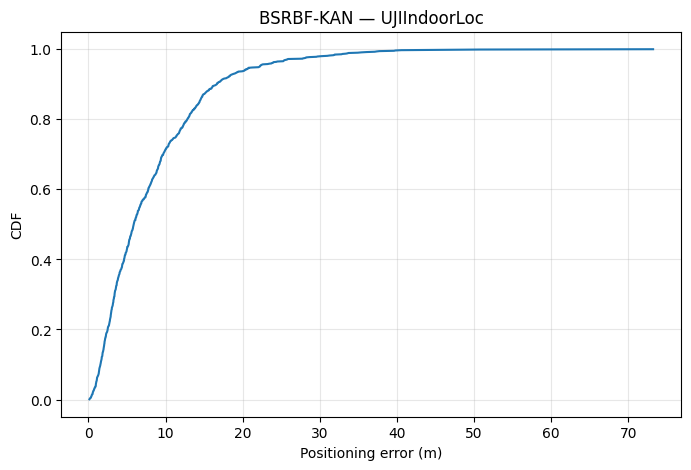

In [ ]:
sorted_errors = np.sort(
    all_errors
)

cdf = (
    np.arange(
        1,
        len(sorted_errors) + 1
    )
    /
    len(sorted_errors)
)

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    sorted_errors,
    cdf
)

plt.xlabel(
    "Positioning error (m)"
)

plt.ylabel(
    "CDF"
)

plt.title(
    "BSRBF-KAN — UJIIndoorLoc"
)

plt.grid(
    alpha=0.3
)

plt.show()

Interval Validation Curve

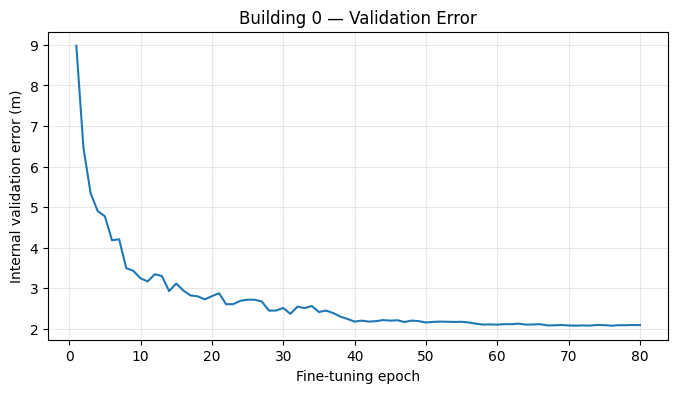

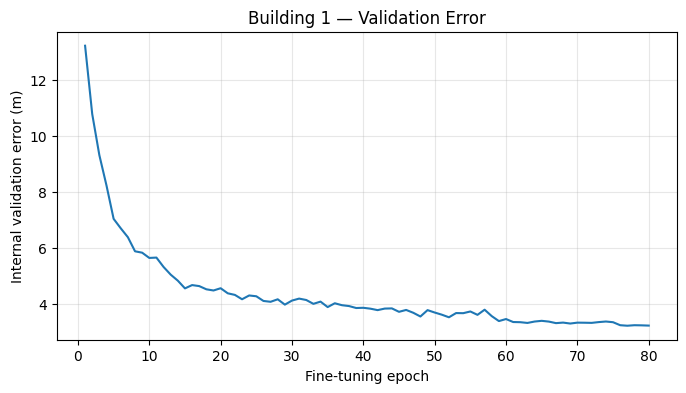

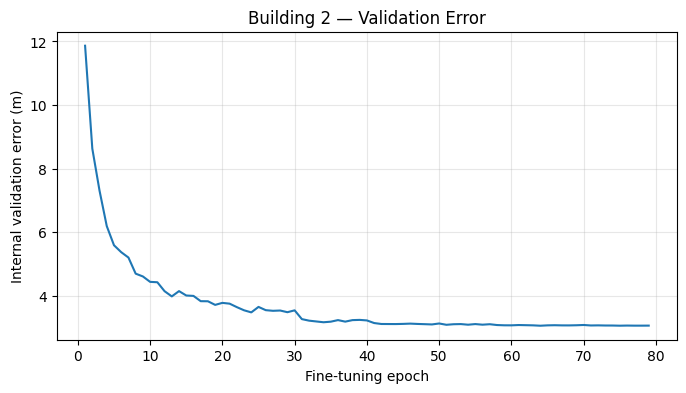


DONE.


In [ ]:
for r in results:

    h = r["history"]

    plt.figure(
        figsize=(8, 4)
    )

    plt.plot(
        range(
            1,
            len(h["val_error"]) + 1
        ),
        h["val_error"]
    )

    plt.xlabel(
        "Fine-tuning epoch"
    )

    plt.ylabel(
        "Internal validation error (m)"
    )

    plt.title(
        f"Building {r['building']} — Validation Error"
    )

    plt.grid(
        alpha=0.3
    )

    plt.show()

print("\nDONE.")